# Projeto Final — Modelos Descritivos
## Equipe 04 · Logística/Comercial — Segmentação de clientes de um e-commerce com clusterização

**Base:** *Online Retail II* (UCI Machine Learning Repository) — todas as transações de um e-commerce do Reino Unido que vende artigos de presente e decoração, de 01/12/2009 a 09/12/2011. Boa parte dos clientes são atacadistas/revendedores.

**Roteiro do notebook**
1. Problemática
2. Carregamento da base
3. Análise exploratória (EDA) e qualidade dos dados
4. Limpeza e tratamento
5. Engenharia de atributos — modelo RFM
6. Pré-processamento (transformação log + padronização)
7. Construção dos clusters — K-Means, Hierárquico (Ward) e DBSCAN
8. Avaliação dos clusters (Inércia/Cotovelo, Silhueta, Davies-Bouldin, Calinski-Harabasz)
9. Descrição detalhada de cada cluster
10. Conclusões e recomendações para o CEO

> **Como rodar no Google Colab:** execute as células em ordem (*Ambiente de execução → Executar tudo*). Na célula de carregamento, cole o link *raw* do `.zip` no GitHub do grupo **ou** deixe em branco para fazer upload manual do arquivo `online_retail_II.csv.zip`.

## 1. Problemática

A empresa tem quase **6 mil clientes identificados** e trata todos da mesma forma: mesmo catálogo, mesmas campanhas, mesma política comercial. Só que os clientes são muito diferentes entre si — alguns compram toda semana e geram a maior parte da receita, outros compraram uma única vez e nunca voltaram.

**Pergunta de negócio:**
> *Quais grupos de clientes com comportamento de compra parecido existem na base, quanto cada grupo vale para a empresa e que ação comercial faz sentido para cada um?*

**Por que clusterização?** Não temos um rótulo pronto dizendo "este cliente é VIP" ou "este está indo embora". Queremos que os **próprios dados revelem os grupos** — é exatamente o cenário de aprendizado **não supervisionado (descritivo)**. O resultado vira insumo para marketing (campanhas segmentadas), comercial (priorização da carteira) e logística/estoque (quais produtos sustentam os clientes mais valiosos).

**Unidade de análise:** o **cliente**. Cada linha da base original é um item de nota fiscal, então vamos agregar as transações por cliente e descrever cada um pelo modelo **RFM** (Recência, Frequência e valor Monetário), clássico em CRM/varejo.

### Bibliotecas
Usamos `pandas`/`numpy` para manipulação, `matplotlib`/`seaborn` para gráficos e `scikit-learn`/`scipy` para os algoritmos de clusterização e as métricas de avaliação.

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 5)

SEED = 42  # semente fixa para os resultados serem reprodutíveis

## 2. Carregamento da base

A base tem ~1 milhão de linhas (95 MB descompactada). Por isso guardamos no GitHub o arquivo **compactado** (`.zip`, ~15 MB) — o `pandas` lê o CSV direto de dentro do zip.

Dicionário de dados:

| Coluna | Significado |
|---|---|
| `Invoice` | Número da nota fiscal. Se começa com **"C"**, é um **cancelamento/devolução** |
| `StockCode` | Código do produto |
| `Description` | Nome do produto |
| `Quantity` | Quantidade por item da nota (negativa em devoluções) |
| `InvoiceDate` | Data e hora da compra |
| `Price` | Preço unitário (libras esterlinas, £) |
| `Customer ID` | Código do cliente |
| `Country` | País do cliente |

In [2]:
# Opção 1 (recomendada): cole aqui o link "raw" do arquivo .zip no GitHub do grupo
URL_GITHUB = ""   # ex.: "https://github.com/<usuario>/<repo>/raw/main/online_retail_II.csv.zip"
ARQUIVO_LOCAL = "online_retail_II.csv.zip"

if URL_GITHUB:
    fonte = URL_GITHUB
elif os.path.exists(ARQUIVO_LOCAL):
    fonte = ARQUIVO_LOCAL
else:
    # Opção 2: upload manual do .zip pelo Colab
    from google.colab import files
    enviado = files.upload()
    fonte = next(iter(enviado))

# O pandas lê o .zip diretamente (o CSV está dentro dele)
df_raw = pd.read_csv(fonte, dtype={"Invoice": str, "StockCode": str})
df_raw["InvoiceDate"] = pd.to_datetime(df_raw["InvoiceDate"])
print(f"{df_raw.shape[0]:,} linhas x {df_raw.shape[1]} colunas")
df_raw.head()

Saving online_retail_II.csv.zip to online_retail_II.csv.zip
1,067,371 linhas x 8 colunas


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## 3. Análise exploratória (EDA)

### 3.1 Visão geral
  tamanho, tipos, período coberto e quantas entidades distintas existem (notas, produtos, clientes, países).

In [3]:
df_raw.info()
print("\nPeríodo:", df_raw["InvoiceDate"].min(), "→", df_raw["InvoiceDate"].max())
print("Notas fiscais distintas:", df_raw["Invoice"].nunique())
print("Produtos distintos:", df_raw["StockCode"].nunique())
print("Clientes distintos:", df_raw["Customer ID"].nunique())
print("Países:", df_raw["Country"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB

Período: 2009-12-01 07:45:00 → 2011-12-09 12:50:00
Notas fiscais distintas: 53628
Produtos distintos: 5305
Clientes distintos: 5942
Países: 43


**O que vemos:** são ~1,07 milhão de itens de nota, ~53 mil notas fiscais, ~5,3 mil produtos e ~5,9 mil clientes em 43 países, cobrindo **dois anos completos** (dez/2009 a dez/2011). Os tipos estão corretos depois de convertermos `InvoiceDate` para data.

### 3.2 Qualidade dos dados — inconsistências
Verificamos valores nulos, duplicatas, cancelamentos e valores impossíveis (quantidade ou preço ≤ 0).

In [4]:
qualidade = pd.DataFrame({
    "nulos": df_raw.isna().sum(),
    "% nulos": (df_raw.isna().mean() * 100).round(2),
})
print(qualidade, "\n")

cancel = df_raw["Invoice"].str.startswith("C")
print(f"Linhas duplicadas: {df_raw.duplicated().sum():,}")
print(f"Linhas de cancelamento (Invoice começa com 'C'): {cancel.sum():,}")
print(f"Linhas com Quantity <= 0: {(df_raw['Quantity'] <= 0).sum():,}")
print(f"Linhas com Price <= 0: {(df_raw['Price'] <= 0).sum():,}")

df_raw[["Quantity", "Price"]].describe(percentiles=[.01, .25, .5, .75, .99])

              nulos  % nulos
Invoice           0     0.00
StockCode         0     0.00
Description    4382     0.41
Quantity          0     0.00
InvoiceDate       0     0.00
Price             0     0.00
Customer ID  243007    22.77
Country           0     0.00 

Linhas duplicadas: 34,335
Linhas de cancelamento (Invoice começa com 'C'): 19,494
Linhas com Quantity <= 0: 22,950
Linhas com Price <= 0: 6,207


,Quantity,Price
count,"1,067,371.00","1,067,371.00"
mean,9.94,4.65
std,172.71,123.55
min,"-80,995.00","-53,594.36"
1%,-3.00,0.21
25%,1.00,1.25
50%,3.00,2.10
75%,10.00,4.15
99%,100.00,18.00
max,"80,995.00","38,970.00"


**Problemas encontrados:**
- **~23% das linhas não têm `Customer ID`** (provavelmente compras sem cadastro). Como nossa análise é **por cliente**, essas linhas não podem ser usadas.
- **~34 mil linhas duplicadas** — o mesmo item lançado duas vezes na mesma nota.
- **~19,5 mil linhas de cancelamento** (notas com "C"), com quantidade negativa. Não são erro: representam **devoluções** e serão usadas para calcular o valor *líquido* e a taxa de devolução de cada cliente.
- **Preço ≤ 0** e quantidades absurdas (±80.995) — os extremos são pedidos digitados errado e cancelados logo em seguida.
- A distribuição de `Quantity` e `Price` é **muito assimétrica** (99% das linhas têm quantidade ≤ 100, mas o máximo passa de 80 mil).

Alguns `StockCode` não são produtos, e sim **lançamentos administrativos** (frete, taxas bancárias, descontos, ajustes, comissões). Eles distorcem o comportamento de compra e precisam sair:

In [5]:
# Códigos que NÃO são produtos (frete, taxas, ajustes, amostras...)
nao_produto = df_raw[~df_raw["StockCode"].str.match(r"^\d{5}")]
nao_produto.groupby(["StockCode"])["Description"].first().head(25)

,Description
StockCode,
ADJUST,Adjustment by john on 26/01/2010 16
ADJUST2,Adjustment by Peter on Jun 25 2010
AMAZONFEE,AMAZON FEE
B,Adjust bad debt
BANK CHARGES,Bank Charges
C2,CARRIAGE
C3,None
CRUK,CRUK Commission
D,Discount


## 4. Limpeza e tratamento

Decisões tomadas (e por quê):

| Etapa | Justificativa |
|---|---|
| Remover linhas sem `Customer ID` | Sem cliente não há como montar o perfil RFM |
| Remover duplicatas | Evita contar o mesmo item duas vezes |
| Remover códigos de serviço (`POST`, `DOT`, `M`, `BANK CHARGES`, `AMAZONFEE`, `gift_`, `DCGS`...) | Não representam compra de produto |
| Remover preço ≤ 0 | Brindes/ajustes sem valor comercial |
| **Separar** vendas e cancelamentos | Vendas formam o comportamento de compra; cancelamentos viram "devoluções" do cliente |

Também criamos a coluna `Valor = Quantity × Price`.

In [6]:
CODIGOS_SERVICO = ["POST", "DOT", "M", "C2", "D", "S", "B", "BANK CHARGES", "ADJUST",
                   "ADJUST2", "AMAZONFEE", "PADS", "CRUK", "TEST001", "TEST002", "m"]

df = df_raw.copy()
n0 = len(df)
etapas = []

df = df.dropna(subset=["Customer ID"]);              etapas.append(("Sem Customer ID", n0 - len(df))); n1 = len(df)
df = df.drop_duplicates();                           etapas.append(("Duplicadas", n1 - len(df))); n2 = len(df)
df = df[~df["StockCode"].isin(CODIGOS_SERVICO)]
df = df[~df["StockCode"].str.startswith(("gift_", "DCGS"))]
etapas.append(("Códigos de serviço/taxa", n2 - len(df))); n3 = len(df)
df = df[df["Price"] > 0];                            etapas.append(("Preço <= 0", n3 - len(df)))

df["Customer ID"] = df["Customer ID"].astype(int)
df["Cancelada"] = df["Invoice"].str.startswith("C")
df["Valor"] = df["Quantity"] * df["Price"]

vendas = df[~df["Cancelada"] & (df["Quantity"] > 0)].copy()
devolucoes = df[df["Cancelada"]].copy()

print(pd.DataFrame(etapas, columns=["Etapa", "Linhas removidas"]).to_string(index=False))
print(f"\nBase limpa: {len(df):,} linhas ({len(df)/n0:.1%} da original)")
print(f"  - vendas: {len(vendas):,} linhas | devoluções: {len(devolucoes):,} linhas")

                  Etapa  Linhas removidas
        Sem Customer ID            243007
             Duplicadas             26479
Códigos de serviço/taxa              3660
             Preço <= 0                60

Base limpa: 794,165 linhas (74.4% da original)
  - vendas: 776,579 linhas | devoluções: 17,586 linhas


Ficamos com **~74% das linhas originais**. A maior perda vem dos registros sem cliente — uma limitação da base que precisa ser citada: os grupos descrevem **clientes cadastrados**, não 100% das vendas.

### 3.3 (cont.) EDA na base limpa — sazonalidade
Agora que a base está limpa, olhamos padrões de negócio que ajudam a interpretar os clusters depois.

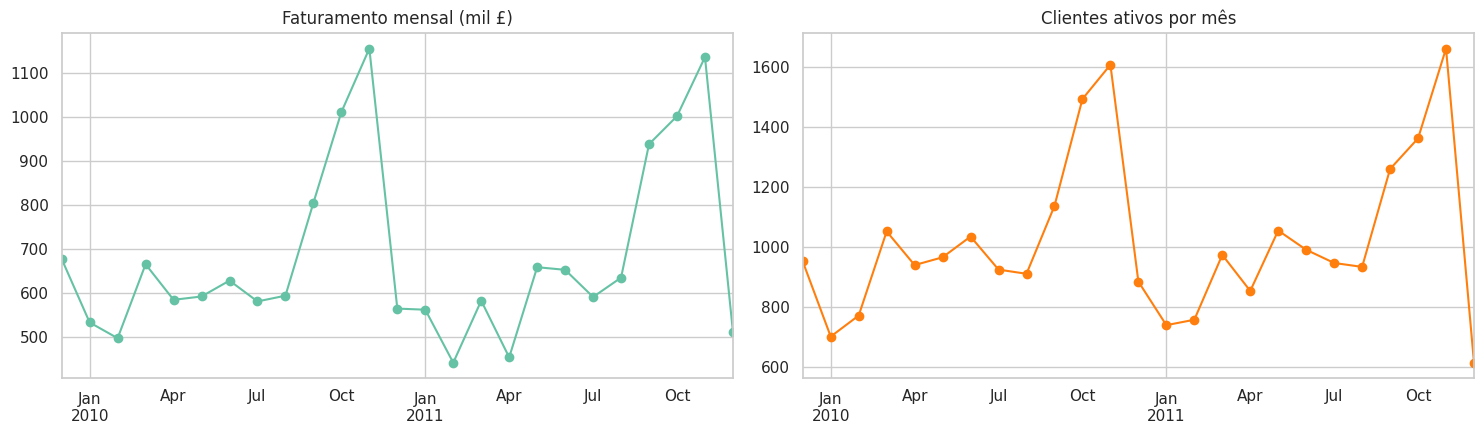

In [7]:
vendas["Mes"] = vendas["InvoiceDate"].dt.to_period("M")
mensal = vendas.groupby("Mes").agg(Faturamento=("Valor", "sum"),
                                    Pedidos=("Invoice", "nunique"),
                                    Clientes=("Customer ID", "nunique"))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
(mensal["Faturamento"] / 1e3).plot(ax=ax[0], marker="o")
ax[0].set_title("Faturamento mensal (mil £)"); ax[0].set_xlabel("")
mensal["Clientes"].plot(ax=ax[1], marker="o", color="tab:orange")
ax[1].set_title("Clientes ativos por mês"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

**Forte sazonalidade de fim de ano:** o faturamento e o número de clientes ativos sobem a partir de setembro e atingem o pico em **novembro** — faz sentido para uma loja de presentes/decoração cujos clientes são revendedores se abastecendo para o Natal. A queda em dez/2011 ocorre porque a base termina no dia 09/12 (mês incompleto).

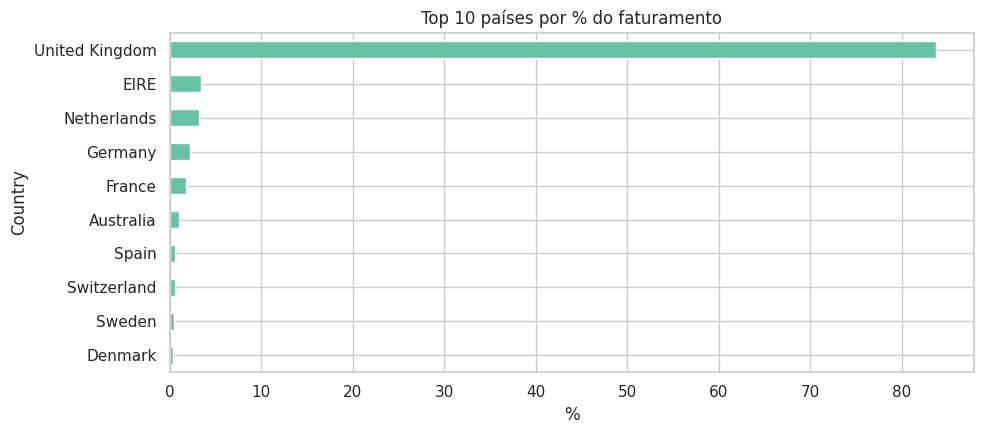

,Faturamento,Clientes,% Faturamento
Country,,,
United Kingdom,"14,288,773.50",5334,83.71
EIRE,"586,626.08",3,3.44
Netherlands,"549,773.41",22,3.22
Germany,"383,289.00",107,2.25
France,"309,403.16",93,1.81
Australia,"167,800.01",15,0.98
Spain,"97,766.75",38,0.57
Switzerland,"93,400.94",22,0.55
Sweden,"86,045.14",19,0.50


In [8]:
pais = (vendas.groupby("Country")
        .agg(Faturamento=("Valor", "sum"), Clientes=("Customer ID", "nunique"))
        .sort_values("Faturamento", ascending=False))
pais["% Faturamento"] = pais["Faturamento"] / pais["Faturamento"].sum() * 100

fig, ax = plt.subplots(figsize=(10, 4.5))
pais.head(10)["% Faturamento"][::-1].plot.barh(ax=ax)
ax.set_title("Top 10 países por % do faturamento"); ax.set_xlabel("%")
plt.tight_layout(); plt.show()
pais.head(10)

O **Reino Unido concentra ~84% do faturamento** e ~91% dos clientes. Alguns países têm poucos clientes com volume enorme (a Irlanda — EIRE — tem só 3 clientes e é o 2º maior mercado), um indício de compradores atacadistas.

Produtos mais vendidos (valor **líquido** das devoluções — usamos o líquido porque existem pedidos gigantes que foram lançados e cancelados no mesmo dia):

In [9]:
# Valor LÍQUIDO (vendas - devoluções) para não inflar produtos com pedidos cancelados
top_prod = (df.groupby("Description")
            .agg(Faturamento=("Valor", "sum"), Quantidade=("Quantity", "sum"))
            .sort_values("Faturamento", ascending=False).head(10))
top_prod

,Faturamento,Quantidade
Description,,
REGENCY CAKESTAND 3 TIER,"261,110.95",22674
WHITE HANGING HEART T-LIGHT HOLDER,"237,678.61",88126
JUMBO BAG RED RETROSPOT,"132,180.02",73033
ASSORTED COLOUR BIRD ORNAMENT,"123,631.87",77755
PARTY BUNTING,"102,089.38",23184
PAPER CHAIN KIT 50'S CHRISTMAS,"75,388.48",27910
CHILLI LIGHTS,"68,453.50",14699
JUMBO BAG STRAWBERRY,"63,615.53",35559
BLACK RECORD COVER FRAME,"63,009.83",18394


Quando os pedidos acontecem?

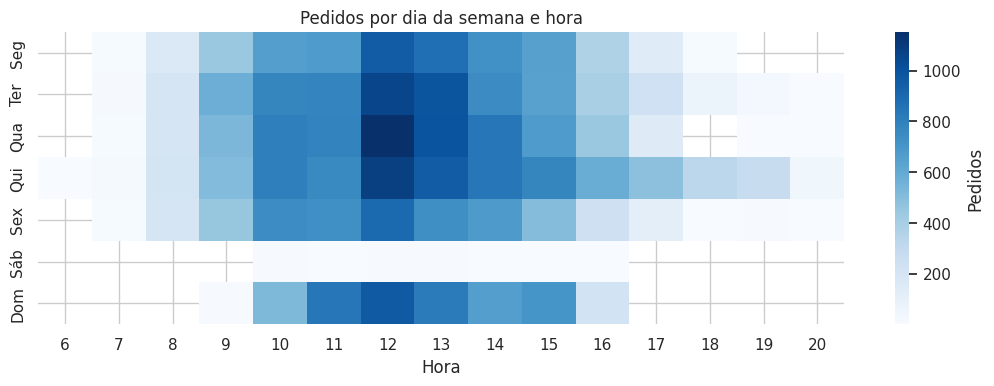

In [10]:
dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
vendas["DiaSemana"] = vendas["InvoiceDate"].dt.dayofweek
vendas["Hora"] = vendas["InvoiceDate"].dt.hour
mapa = vendas.pivot_table(index="DiaSemana", columns="Hora", values="Invoice",
                          aggfunc="nunique").reindex(range(7))
mapa.index = dias

plt.figure(figsize=(13, 3.8))
sns.heatmap(mapa, cmap="Blues", cbar_kws={"label": "Pedidos"})
plt.title("Pedidos por dia da semana e hora"); plt.ylabel(""); plt.show()

Os pedidos se concentram em **dias úteis, entre 10h e 15h**, e praticamente **não há pedidos aos sábados**. Comportamento típico de cliente **empresa** (B2B), não de consumidor final — reforça que estamos segmentando uma carteira de revendedores.

## 5. Engenharia de atributos — modelo RFM

Agregamos as transações por cliente. As **três variáveis usadas no agrupamento** são:

- **Recência (R):** dias desde a última compra até a data de referência (dia seguinte à última venda da base). *Menor = melhor.*
- **Frequência (F):** número de notas fiscais (pedidos) distintas.
- **Monetário (M):** valor **líquido** gasto (compras − devoluções), em £.

**Por que só RFM no modelo?** É o modelo mais consolidado em segmentação de clientes, as três dimensões têm leitura direta para o negócio e poucas variáveis evitam que a distância euclidiana seja dominada por atributos redundantes.

Calculamos também **variáveis descritivas** que *não* entram no algoritmo, mas servem para **interpretar** os clusters depois: ticket médio, variedade de produtos comprados, antiguidade do cliente, taxa de devolução e país.

In [11]:
DATA_REF = vendas["InvoiceDate"].max() + pd.Timedelta(days=1)

clientes = vendas.groupby("Customer ID").agg(
    Recencia=("InvoiceDate", lambda s: (DATA_REF - s.max()).days),
    Frequencia=("Invoice", "nunique"),
    Bruto=("Valor", "sum"),
    PrimeiraCompra=("InvoiceDate", "min"),
    Variedade=("StockCode", "nunique"),
    Itens=("Quantity", "sum"),
    Pais=("Country", lambda s: s.mode().iat[0]),
)
# Devoluções: valor devolvido por cliente (positivo)
dev = devolucoes.groupby("Customer ID")["Valor"].sum().abs().reindex(clientes.index).fillna(0)
clientes["TaxaDevolucao"] = (dev / clientes["Bruto"]).clip(upper=1)
# Monetário LÍQUIDO = compras - devoluções (evita contar pedidos gigantes que foram cancelados)
clientes["Monetario"] = clientes["Bruto"] - dev

n_antes = len(clientes)
clientes = clientes[clientes["Monetario"] >= 1].copy()   # quem devolveu (quase) tudo sai da análise
clientes["TicketMedio"] = clientes["Monetario"] / clientes["Frequencia"]
clientes["Antiguidade"] = (DATA_REF - clientes["PrimeiraCompra"]).dt.days
clientes["ReinoUnido"] = (clientes["Pais"] == "United Kingdom")

print(f"Data de referência: {DATA_REF.date()}")
print(f"Clientes: {len(clientes):,} (removidos {n_antes - len(clientes)} com valor líquido < £1)")
clientes.describe(percentiles=[.25, .5, .75, .95, .99]).T

Data de referência: 2011-12-10
Clientes: 5,832 (removidos 20 com valor líquido < £1)


,count,mean,min,25%,50%,75%,95%,99%,max,std
Recencia,"5,832.00",199.85,1.00,25.00,95.00,379.00,623.45,726.00,738.00,208.37
Frequencia,"5,832.00",6.27,1.00,1.00,3.00,7.00,20.00,46.00,373.00,12.77
Bruto,"5,832.00","2,925.59",2.95,342.24,861.71,"2,245.94","9,279.52","28,729.65","580,987.04","14,330.55"
PrimeiraCompra,5832,2010-08-22 12:57:02.633744896,2009-12-01 07:45:00,2010-02-10 12:22:15,2010-06-28 11:46:30,2011-01-31 13:48:45,2011-10-19 14:26:09,2011-11-24 14:28:59.400000,2011-12-09 12:16:00,NaN
Variedade,"5,832.00",82.42,1.00,19.00,45.00,104.00,281.90,503.38,"2,546.00",116.62
Itens,"5,832.00","1,799.44",1.00,190.00,486.50,"1,363.25","5,359.50","16,774.84","367,072.00","8,905.57"
TaxaDevolucao,"5,832.00",0.02,0.00,0.00,0.00,0.01,0.10,0.29,1.00,0.06
Monetario,"5,832.00","2,805.48",2.90,333.79,843.74,"2,179.89","8,928.42","26,543.84","578,408.64","13,847.92"
TicketMedio,"5,832.00",356.49,1.45,172.90,272.22,403.53,841.28,"1,809.10","13,206.50",474.07
Antiguidade,"5,832.00",474.46,1.00,312.00,530.00,668.00,736.00,738.00,739.00,223.02


Pela tabela, a mediana de compras por cliente é **3 pedidos**, mas há clientes com centenas. O valor gasto tem mediana de ~£850 e máximo de centenas de milhares de libras. Os clientes que devolveram tudo o que compraram (valor líquido < £1) foram removidos — não têm comportamento de compra a agrupar.

### Distribuição das variáveis RFM
O K-Means usa distância euclidiana e é **sensível a escalas e a valores extremos**. Vamos ver como as variáveis se distribuem antes e depois de uma transformação logarítmica.

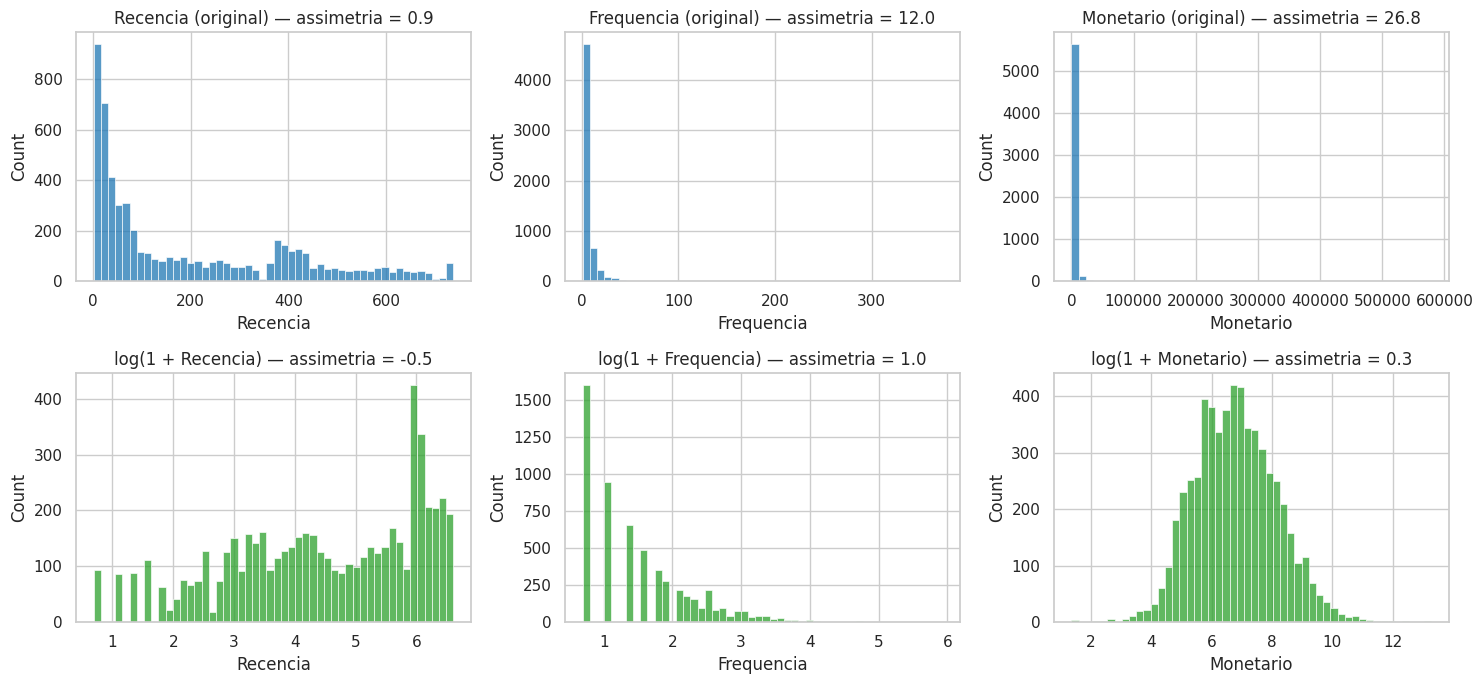

In [12]:
RFM = ["Recencia", "Frequencia", "Monetario"]

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for i, c in enumerate(RFM):
    sns.histplot(clientes[c], bins=50, ax=ax[0, i], color="tab:blue")
    ax[0, i].set_title(f"{c} (original) — assimetria = {clientes[c].skew():.1f}")
    sns.histplot(np.log1p(clientes[c]), bins=50, ax=ax[1, i], color="tab:green")
    ax[1, i].set_title(f"log(1 + {c}) — assimetria = {np.log1p(clientes[c]).skew():.1f}")
plt.tight_layout(); plt.show()

**Decisão — transformação `log(1+x)`:** Frequência e Monetário têm assimetria muito alta (≈12 e ≈27). Sem tratamento, uns poucos clientes gigantes "puxariam" os centróides e o algoritmo criaria clusters de 1 ou 2 pessoas. Depois do log, as distribuições ficam muito mais simétricas.

Preferimos o **log a remover outliers** porque, neste negócio, os clientes extremos são justamente os mais valiosos — não podemos descartá-los.

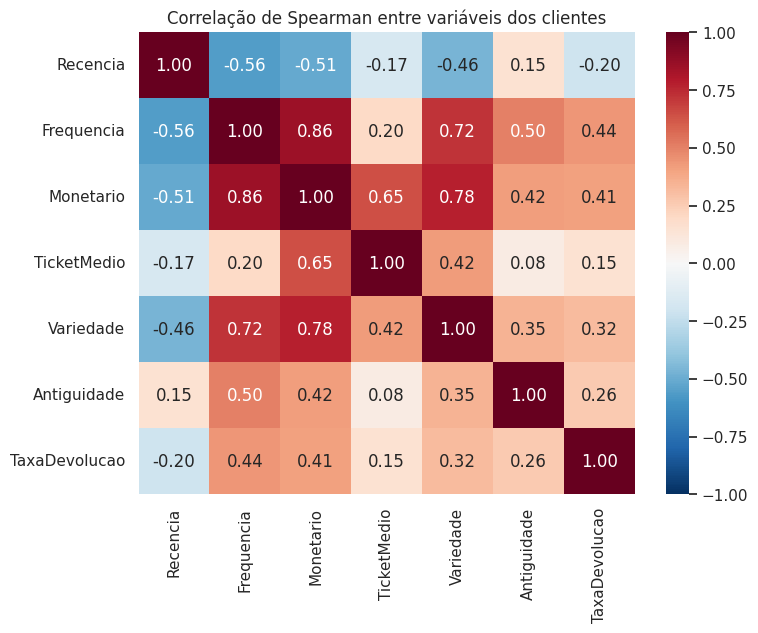

In [13]:
vars_corr = RFM + ["TicketMedio", "Variedade", "Antiguidade", "TaxaDevolucao"]
plt.figure(figsize=(8, 6))
sns.heatmap(np.log1p(clientes[vars_corr]).corr(method="spearman"),
            annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlação de Spearman entre variáveis dos clientes"); plt.show()

**Correlação:** Frequência e Monetário são fortemente correlacionadas (0,86) — quem compra mais vezes gasta mais. Recência é negativamente correlacionada com ambas (clientes recentes tendem a ser mais frequentes). Variedade de produtos também acompanha F e M, o que confirma que ela é um bom atributo *descritivo*, mas seria redundante dentro do modelo.

## 6. Pré-processamento

1. `log(1+x)` em R, F e M (justificado acima);
2. **Padronização (`StandardScaler`)**: deixa cada variável com média 0 e desvio 1. Sem isso, Recência (que vai até ~740) pesaria muito mais que Frequência (log ≈ 0 a 6) no cálculo das distâncias.

In [14]:
X_log = np.log1p(clientes[RFM])
scaler = StandardScaler()
X = scaler.fit_transform(X_log)
print("Formato da matriz de entrada:", X.shape)
pd.DataFrame(X, columns=RFM).describe().loc[["mean", "std", "min", "max"]]

Formato da matriz de entrada: (5832, 3)


,Recencia,Frequencia,Monetario
mean,0.00,0.00,0.00
std,1.00,1.00,1.00
min,-2.41,-1.06,-3.95
max,1.39,5.42,4.71


## 7. Construção dos clusters

Testamos **três algoritmos** de famílias diferentes, para comparar:

| Algoritmo | Ideia | Por que testar |
|---|---|---|
| **K-Means** | Particiona em *k* grupos minimizando a distância ao centróide | Rápido, escalável, centróides fáceis de interpretar; ideal para variáveis numéricas contínuas e padronizadas como RFM. **Algoritmo principal.** |
| **Hierárquico aglomerativo (Ward)** | Junta clientes/grupos de baixo para cima minimizando o aumento de variância | Não exige *k* de antemão; o dendrograma ajuda a confirmar quantos grupos existem |
| **DBSCAN** | Agrupa por densidade; pontos isolados viram "ruído" | Não assume grupos esféricos e identifica **outliers** |

### 7.1 Escolha do número de clusters (k) no K-Means
Rodamos o K-Means para k = 2 a 10 e calculamos as métricas vistas em aula:
- **Inércia (SSE) / Cotovelo:** soma das distâncias ao quadrado até o centróide — procuramos o "joelho" da curva;
- **Silhueta** (−1 a 1, **maior é melhor**): quão perto cada ponto está do próprio cluster comparado ao cluster vizinho;
- **Davies-Bouldin** (**menor é melhor**): razão entre dispersão interna e separação entre clusters;
- **Calinski-Harabasz** (**maior é melhor**): razão entre variância entre clusters e dentro dos clusters.

Usamos `n_init=10` (10 inicializações, fica a melhor) e semente fixa para reprodutibilidade.

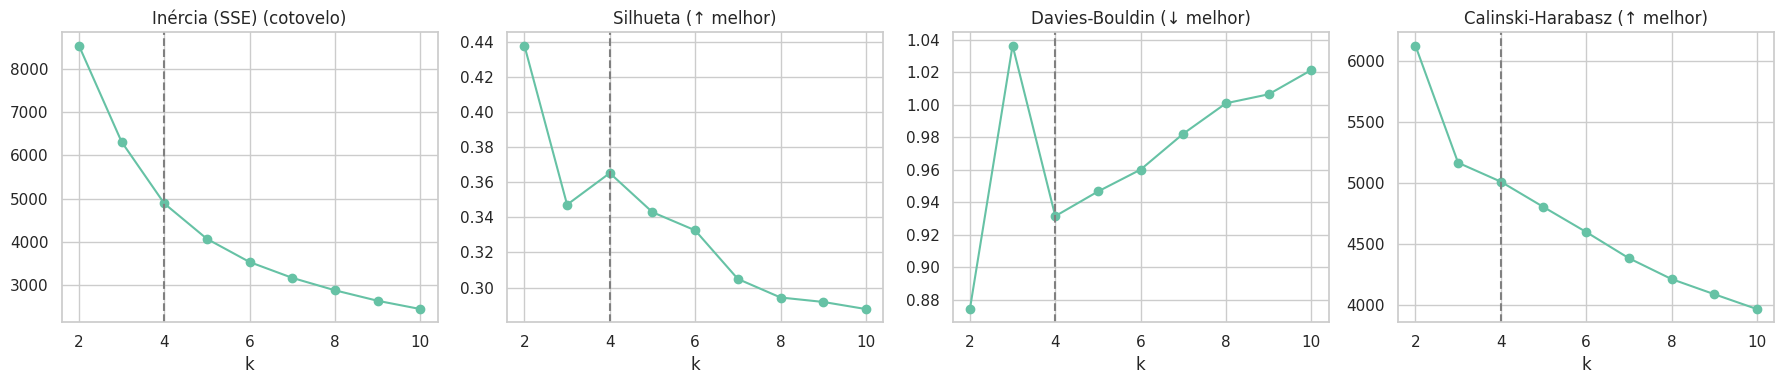

,Inércia (SSE),Silhueta,Davies-Bouldin,Calinski-Harabasz
k,,,,
2,"8,532.52",0.44,0.87,"6,124.50"
3,"6,310.38",0.35,1.04,"5,166.21"
4,"4,887.61",0.37,0.93,"5,011.44"
5,"4,070.76",0.34,0.95,"4,804.35"
6,"3,536.16",0.33,0.96,"4,599.95"
7,"3,171.04",0.30,0.98,"4,385.84"
8,"2,884.20",0.29,1.00,"4,215.10"
9,"2,642.46",0.29,1.01,"4,091.51"
10,"2,451.59",0.29,1.02,"3,969.87"


In [15]:
resultados = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    resultados.append({
        "k": k,
        "Inércia (SSE)": km.inertia_,
        "Silhueta": silhouette_score(X, km.labels_),
        "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
        "Calinski-Harabasz": calinski_harabasz_score(X, km.labels_),
    })
res_k = pd.DataFrame(resultados).set_index("k")

fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, col, dica in zip(ax, res_k.columns, ["cotovelo", "↑ melhor", "↓ melhor", "↑ melhor"]):
    res_k[col].plot(ax=a, marker="o")
    a.set_title(f"{col} ({dica})"); a.axvline(4, ls="--", c="gray")
plt.tight_layout(); plt.show()
res_k

**Escolha: k = 4.** Justificativa:
- **k = 2** tem a melhor silhueta (0,44), mas só separa "ativos" de "inativos" — óbvio demais e pouco acionável para o negócio.
- Entre os valores úteis (k ≥ 3), **k = 4 é um pico local da silhueta** (0,37 contra 0,35 em k=3 e 0,34 em k=5) e um **vale do Davies-Bouldin** (0,93 contra 1,04 em k=3).
- Na curva de **inércia**, o ganho ao passar de 3→4 ainda é grande e a curva começa a achatar depois de 4 (**cotovelo**).
- Calinski-Harabasz cai continuamente com k (comportamento comum dessa métrica), sem contrariar a escolha.
- **Critério de negócio:** 4 segmentos são suficientes para ações diferentes e poucos o bastante para a equipe comercial operar.

### 7.2 K-Means final (k = 4)
Para que a numeração dos clusters fique estável a cada execução, reordenamos os rótulos do menor para o maior valor gasto: **C0 = menor valor … C3 = maior valor**.

In [16]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)

# Reordena os rótulos do cluster de menor para maior valor gasto (mediana),
# para que a numeração fique estável independentemente da inicialização
ordem = (pd.Series(clientes["Monetario"].values).groupby(kmeans.labels_).median()
         .sort_values().index)
mapa_rotulos = {antigo: novo for novo, antigo in enumerate(ordem)}
clientes["Cluster"] = pd.Series(kmeans.labels_).map(mapa_rotulos).values

print(f"Silhueta: {silhouette_score(X, clientes['Cluster']):.3f}")
print(f"Davies-Bouldin: {davies_bouldin_score(X, clientes['Cluster']):.3f}")
print(f"Calinski-Harabasz: {calinski_harabasz_score(X, clientes['Cluster']):,.0f}")
clientes["Cluster"].value_counts().sort_index().rename("Clientes").to_frame()

Silhueta: 0.365
Davies-Bouldin: 0.931
Calinski-Harabasz: 5,011


,Clientes
Cluster,
0,1952
1,1246
2,1446
3,1188


## 8. Avaliação dos clusters

### 8.1 Silhueta por cluster
A média geral esconde diferenças: vamos ver a silhueta de cada cliente, agrupada por cluster.

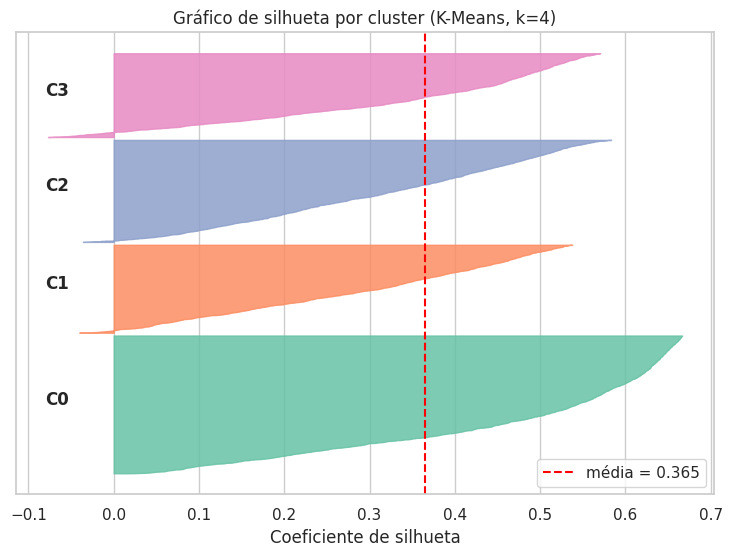

,Silhueta média,Silhueta mínima,% com silhueta < 0
0,0.47,0.02,0.00
1,0.29,-0.04,0.03
2,0.32,-0.04,0.01
3,0.33,-0.08,0.06


In [17]:
sil = silhouette_samples(X, clientes["Cluster"])
fig, ax = plt.subplots(figsize=(9, 6))
y0 = 0
cores = sns.color_palette("Set2", K)
for c in range(K):
    v = np.sort(sil[clientes["Cluster"] == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=cores[c], alpha=.85)
    ax.text(-0.08, y0 + len(v) / 2, f"C{c}", fontweight="bold")
    y0 += len(v) + 40
ax.axvline(sil.mean(), color="red", ls="--", label=f"média = {sil.mean():.3f}")
ax.set_title("Gráfico de silhueta por cluster (K-Means, k=4)")
ax.set_xlabel("Coeficiente de silhueta"); ax.set_yticks([]); ax.legend()
plt.show()

pd.Series(sil).groupby(clientes["Cluster"].values).agg(["mean", "min", lambda s: (s < 0).mean()]) \
  .set_axis(["Silhueta média", "Silhueta mínima", "% com silhueta < 0"], axis=1)

**Leitura:** todos os clusters ficam acima de zero na média e **quase nenhum cliente tem silhueta negativa** (no pior cluster, ~6%). O C0 é o mais bem definido (0,47). Uma silhueta global de ~0,37 indica **estrutura razoável** — esperado para dados de comportamento de clientes, que formam um contínuo e não "ilhas" totalmente separadas. Os grupos são úteis e coerentes, mas há clientes na fronteira entre segmentos (ex.: um "Novo" que está virando "Campeão").

### 8.2 Comparação com o Hierárquico (Ward)
O dendrograma mostra como os clientes vão se juntando. Cortamos a árvore na altura que gera 4 grupos.

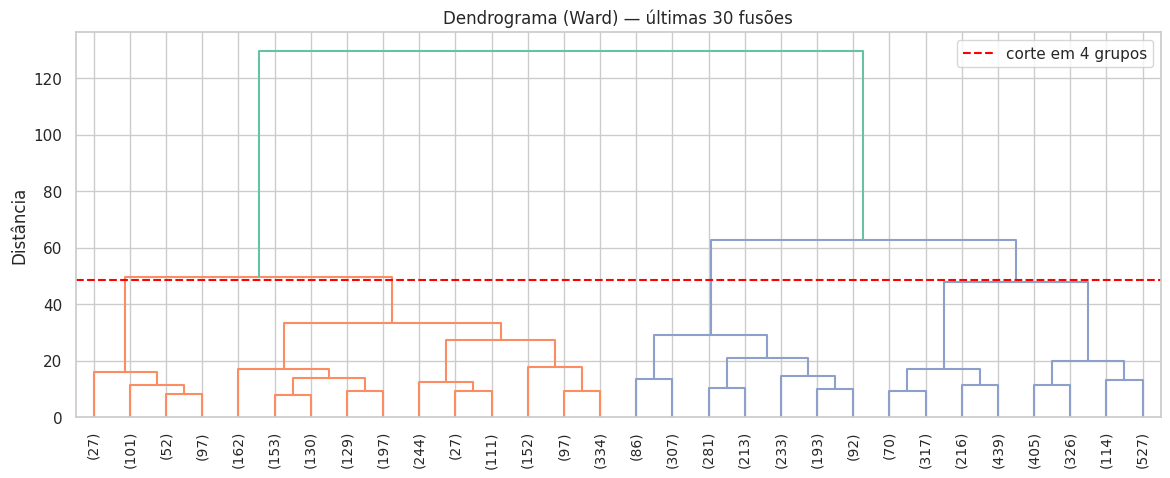

In [18]:
Z = linkage(X, method="ward")
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90, no_labels=False)
plt.axhline((Z[-4, 2] + Z[-3, 2]) / 2, color="red", ls="--", label="corte em 4 grupos")
plt.title("Dendrograma (Ward) — últimas 30 fusões"); plt.ylabel("Distância")
plt.legend(); plt.show()

O dendrograma mostra uma primeira grande divisão (clientes ativos × inativos, coerente com k=2 ser a melhor silhueta) e depois subdivisões bem marcadas — um corte em 4 grupos é razoável também pela visão hierárquica.

In [19]:
comparacao = []
hier_labels = {}
for k in [3, 4, 5]:
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
    hier_labels[k] = lab
    comparacao.append({"k": k,
                       "Silhueta": silhouette_score(X, lab),
                       "Davies-Bouldin": davies_bouldin_score(X, lab),
                       "Calinski-Harabasz": calinski_harabasz_score(X, lab)})
comp_h = pd.DataFrame(comparacao).set_index("k")
print("Hierárquico (Ward):")
print(comp_h, "\n")
print("K-Means k=4:")
print(res_k.loc[[4], ["Silhueta", "Davies-Bouldin", "Calinski-Harabasz"]], "\n")

ari = adjusted_rand_score(clientes["Cluster"], hier_labels[4])
print(f"Concordância K-Means x Hierárquico (Adjusted Rand Index, k=4): {ari:.3f}")
pd.crosstab(clientes["Cluster"], hier_labels[4], rownames=["K-Means"], colnames=["Hierárquico"])

Hierárquico (Ward):
   Silhueta  Davies-Bouldin  Calinski-Harabasz
k                                             
3      0.32            1.09           4,268.60
4      0.30            1.04           3,843.91
5      0.29            0.93           3,944.24 

K-Means k=4:
   Silhueta  Davies-Bouldin  Calinski-Harabasz
k                                             
4      0.37            0.93           5,011.44 

Concordância K-Means x Hierárquico (Adjusted Rand Index, k=4): 0.406


Hierárquico,0,1,2,3
K-Means,,,,
0,1645,0,307,0
1,0,248,998,0
2,769,577,100,0
3,0,911,0,277


**Resultado:** com k=4, o hierárquico tem **métricas piores que o K-Means em todos os critérios** (silhueta ~0,30 vs 0,37; Davies-Bouldin 1,04 vs 0,93; Calinski-Harabasz ~3.840 vs ~5.010). A concordância entre os dois (ARI ≈ 0,41) é moderada: a tabela cruzada mostra que os clientes **inativos** e os **campeões** são reconhecidos pelos dois métodos, e as divergências estão nos grupos intermediários. Isso reforça a escolha do **K-Means**.

### 8.3 DBSCAN — teste de densidade e detecção de outliers
Para escolher `eps`, plotamos a distância de cada ponto ao seu `min_samples`-ésimo vizinho: o "joelho" da curva sugere o raio a usar.

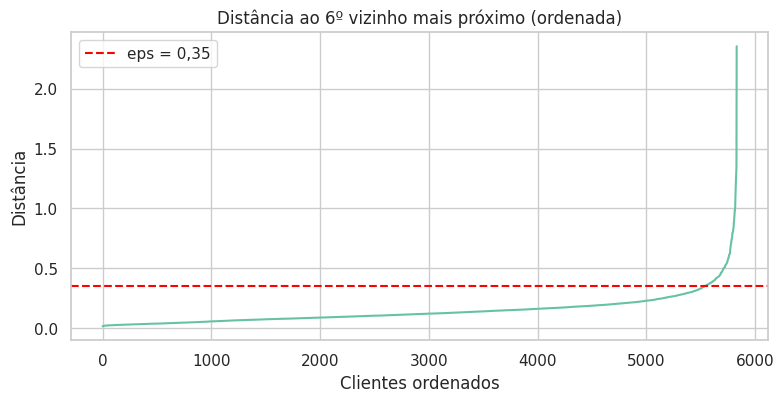

In [20]:
# Escolha do eps pelo gráfico da distância ao k-ésimo vizinho (k = min_samples)
MIN_SAMPLES = 2 * X.shape[1]   # regra prática: 2 x nº de dimensões
dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)
dist_k = np.sort(dist[:, -1])

plt.figure(figsize=(9, 4))
plt.plot(dist_k); plt.axhline(0.35, ls="--", c="red", label="eps = 0,35")
plt.title(f"Distância ao {MIN_SAMPLES}º vizinho mais próximo (ordenada)")
plt.xlabel("Clientes ordenados"); plt.ylabel("Distância"); plt.legend(); plt.show()

In [21]:
db = DBSCAN(eps=0.35, min_samples=MIN_SAMPLES).fit(X)
lab_db = db.labels_
n_clusters_db = len(set(lab_db)) - (1 if -1 in lab_db else 0)
print(f"Clusters encontrados: {n_clusters_db} | Ruído (outliers): {(lab_db == -1).sum()} clientes "
      f"({(lab_db == -1).mean():.1%})")
print(pd.Series(lab_db).value_counts().head(8))

mask = lab_db != -1
if n_clusters_db > 1:
    print(f"\nSilhueta (sem ruído): {silhouette_score(X[mask], lab_db[mask]):.3f}")

# Quem são os outliers do DBSCAN?
clientes.assign(DBSCAN=np.where(lab_db == -1, "Ruído", "Núcleo")) \
        .groupby("DBSCAN")[RFM].median()

Clusters encontrados: 4 | Ruído (outliers): 166 clientes (2.8%)
 0    3164
 1    1569
 2     929
-1     166
 3       4
Name: count, dtype: int64

Silhueta (sem ruído): 0.149


,Recencia,Frequencia,Monetario
DBSCAN,,,
Núcleo,97.00,3.00,827.23
Ruído,31.00,13.50,"10,696.11"


**Resultado:** o DBSCAN coloca a grande maioria dos clientes em um único bloco denso e separa ~3% como **ruído**. A silhueta é baixa (~0,15): como os clientes formam uma **nuvem contínua** (sem regiões de baixa densidade entre grupos), o DBSCAN não é o método adequado para **segmentar** esta base.

Ainda assim, ele traz uma informação útil: os "outliers" são clientes **muito frequentes e de altíssimo valor** (mediana de ~£10 mil gastos vs ~£830 no restante) — ou seja, os pontos "fora do padrão" são os grandes compradores, que no K-Means caem no cluster dos Campeões.

### 8.4 Resumo da comparação

In [22]:
resumo = pd.DataFrame({
    "K-Means (k=4)": [silhouette_score(X, clientes["Cluster"]),
                      davies_bouldin_score(X, clientes["Cluster"]),
                      calinski_harabasz_score(X, clientes["Cluster"])],
    "Hierárquico Ward (k=4)": [silhouette_score(X, hier_labels[4]),
                               davies_bouldin_score(X, hier_labels[4]),
                               calinski_harabasz_score(X, hier_labels[4])],
}, index=["Silhueta (↑)", "Davies-Bouldin (↓)", "Calinski-Harabasz (↑)"])
resumo

,K-Means (k=4),Hierárquico Ward (k=4)
Silhueta (↑),0.37,0.30
Davies-Bouldin (↓),0.93,1.04
Calinski-Harabasz (↑),"5,011.44","3,843.91"


**Decisão final: K-Means com k = 4** — melhores métricas, centróides interpretáveis e resultado estável.

### 8.5 Visualização dos clusters
Reduzimos as 3 dimensões padronizadas para 2 com **PCA**, só para visualização (os 2 componentes explicam ~95% da variância, então a imagem é fiel).

Variância explicada pelos 2 componentes: [0.763 0.188] → total 0.951


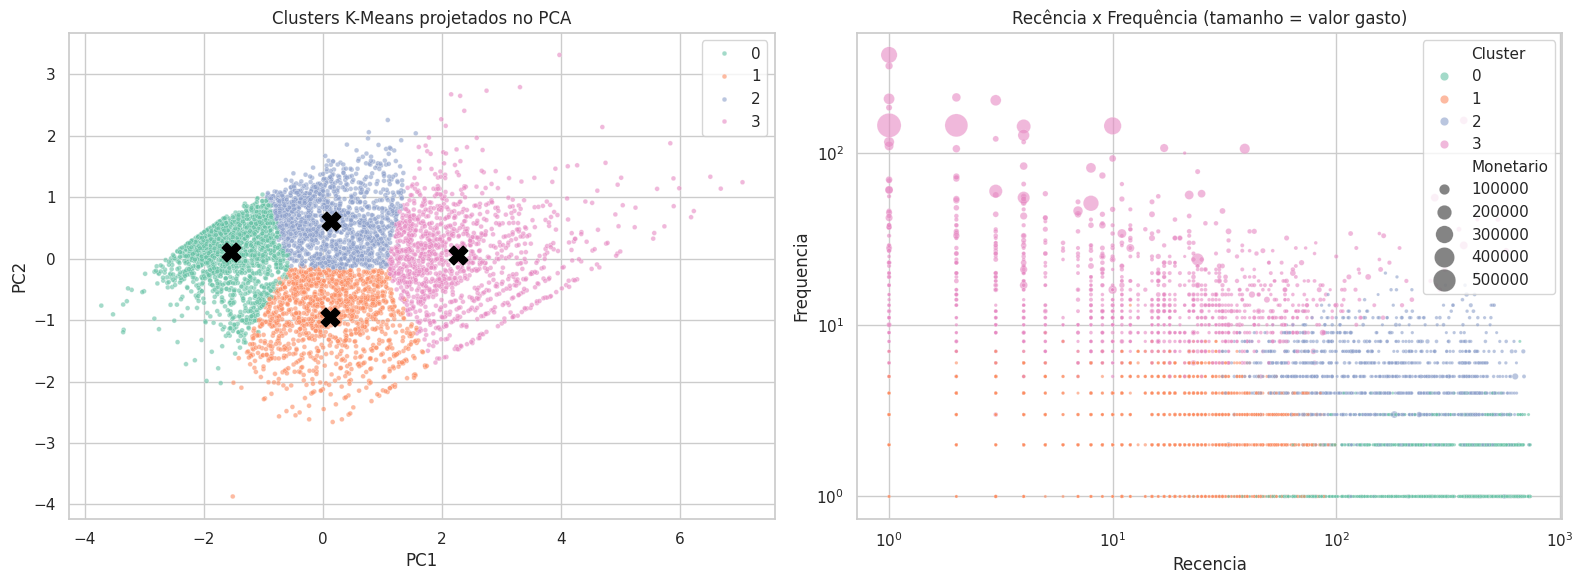

,Recencia,Frequencia,Monetario
PC1,-0.50,0.62,0.60
PC2,0.86,0.30,0.41


In [23]:
pca = PCA(n_components=2, random_state=SEED)
P = pca.fit_transform(X)
print("Variância explicada pelos 2 componentes:", pca.explained_variance_ratio_.round(3),
      "→ total", pca.explained_variance_ratio_.sum().round(3))

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=clientes["Cluster"].values, palette="Set2",
                s=12, alpha=.6, ax=ax[0])
centros_pca = pca.transform(pd.DataFrame(X).groupby(clientes["Cluster"].values).mean())
ax[0].scatter(centros_pca[:, 0], centros_pca[:, 1], c="black", s=180, marker="X")
ax[0].set_title("Clusters K-Means projetados no PCA"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2")

sns.scatterplot(data=clientes, x="Recencia", y="Frequencia", hue="Cluster", palette="Set2",
                size="Monetario", sizes=(5, 300), alpha=.6, ax=ax[1])
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_title("Recência x Frequência (tamanho = valor gasto)")
plt.tight_layout(); plt.show()

pd.DataFrame(pca.components_, columns=RFM, index=["PC1", "PC2"]).round(2)

**Leitura do PCA:** PC1 é basicamente "**engajamento**" (Frequência e Monetário altos, Recência baixa) e PC2 separa clientes **antigos** de **recentes**. Os 4 clusters ocupam regiões distintas do plano: C0 à esquerda (pouco engajados), C3 à direita (muito engajados), C1 e C2 no meio — separados pela recência (C1 embaixo = comprou há pouco; C2 em cima = comprou há mais tempo).

## 9. Descrição detalhada de cada cluster

Usamos **medianas** (mais robustas que médias, dado o tamanho dos outliers) e as variáveis descritivas que não entraram no modelo.

In [24]:
perfil = clientes.groupby("Cluster").agg(
    Clientes=("Recencia", "size"),
    Recencia_mediana=("Recencia", "median"),
    Frequencia_mediana=("Frequencia", "median"),
    Monetario_mediano=("Monetario", "median"),
    TicketMedio_mediano=("TicketMedio", "median"),
    Variedade_mediana=("Variedade", "median"),
    Antiguidade_mediana=("Antiguidade", "median"),
    TaxaDevolucao_media=("TaxaDevolucao", "mean"),
    Pct_ReinoUnido=("ReinoUnido", "mean"),
    Faturamento_total=("Monetario", "sum"),
)
perfil.insert(1, "% Clientes", perfil["Clientes"] / perfil["Clientes"].sum() * 100)
perfil["% Faturamento"] = perfil["Faturamento_total"] / perfil["Faturamento_total"].sum() * 100
perfil["Pct_ReinoUnido"] *= 100
perfil["TaxaDevolucao_media"] *= 100
perfil.T

Cluster,0,1,2,3
Clientes,"1,952.00","1,246.00","1,446.00","1,188.00"
% Clientes,33.47,21.36,24.79,20.37
Recencia_mediana,402.00,24.00,182.50,16.00
Frequencia_mediana,1.00,3.00,4.50,13.00
Monetario_mediano,266.42,703.41,"1,432.42","4,811.66"
TicketMedio_mediano,196.77,246.62,310.88,359.97
Variedade_mediana,17.50,43.00,64.00,165.00
Antiguidade_mediana,443.00,218.00,619.00,677.00
TaxaDevolucao_media,2.09,1.51,2.30,2.09
Pct_ReinoUnido,92.73,90.77,90.18,90.40


A partir do perfil, damos um **nome de negócio** a cada cluster:

In [25]:
# Nomes de negócio atribuídos a partir do perfil acima (ordem: menor → maior valor gasto)
NOMES = {
    0: "C0 · Perdidos / Inativos",
    1: "C1 · Novos e Recentes",
    2: "C2 · Em Risco (bons clientes sumindo)",
    3: "C3 · Campeões",
}
clientes["Segmento"] = clientes["Cluster"].map(NOMES)
ORDEM_SEG = [NOMES[i] for i in range(K)]
clientes["Segmento"].value_counts().reindex(ORDEM_SEG)

,count
Segmento,
C0 · Perdidos / Inativos,1952
C1 · Novos e Recentes,1246
C2 · Em Risco (bons clientes sumindo),1446
C3 · Campeões,1188


### Perfil de cada segmento

**C3 · Campeões (~20% dos clientes → ~74% do faturamento)**
Compraram há poucos dias (mediana ~16 dias), fazem muitos pedidos (mediana 13 em dois anos), gastam muito (mediana ~£4,8 mil), compram a maior variedade de produtos (~166 itens diferentes) e são clientes antigos (~680 dias de casa). É o núcleo do negócio — **perder alguns deles custa caro**.

**C2 · Em Risco — bons clientes sumindo (~25% → ~16%)**
Têm histórico bom (mediana de 4–5 pedidos e ~£1,4 mil gastos, cliente há ~620 dias), mas **não compram há ~6 meses** (mediana ~183 dias). Já foram clientes relevantes; muitos compraram forte no Natal de 2010 e não voltaram. É o grupo onde **reativação traz mais retorno**.

**C1 · Novos e Recentes (~21% → ~6%)**
Compraram recentemente (mediana ~24 dias), poucos pedidos até agora (~3) e gasto moderado (~£700). São clientes **novos** (antiguidade mediana ~220 dias): muitos entraram na temporada de 2011 — o gráfico de faturamento por segmento mostra este grupo crescendo forte no fim de 2011. Têm a **menor taxa de devolução**. São os candidatos a virar Campeões.

**C0 · Perdidos / Inativos (~33% → ~4%)**
Maior grupo em número de clientes, mas o menor em receita. Compraram **uma única vez** (mediana), há mais de um ano (~400 dias), com ticket e variedade baixos. São clientes pontuais que não criaram vínculo.

**Diferenças-chave:**
- A **Recência** separa C1 (recente) de C2 (afastado), que têm volume parecido;
- **Frequência e Variedade** separam os Campeões de todos os outros;
- O **país não diferencia** os clusters (~90% Reino Unido em todos) — o comportamento de compra importa mais que a geografia;
- O **ticket médio cresce** de C0 para C3, mas bem menos que o valor total: os Campeões gastam mais principalmente porque **compram mais vezes**, não porque fazem pedidos muito maiores.

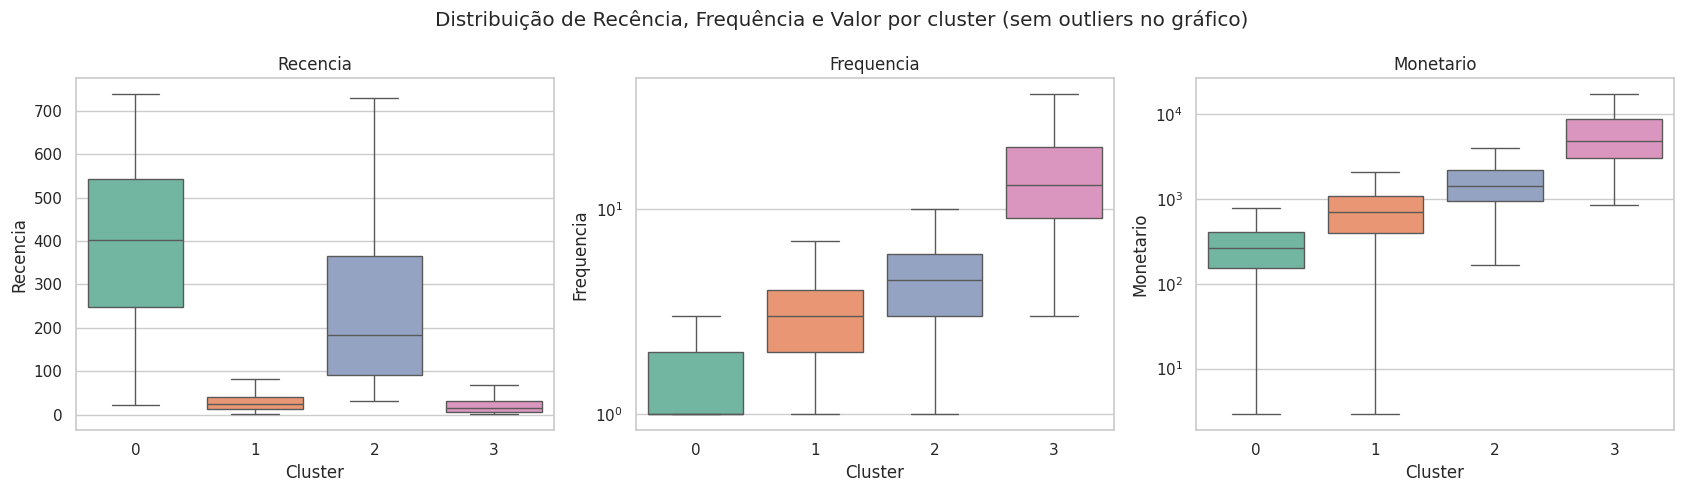

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, c in zip(ax, RFM):
    sns.boxplot(data=clientes, x="Cluster", y=c, ax=a, palette="Set2", showfliers=False)
    a.set_title(c)
    if c != "Recencia":
        a.set_yscale("log")
plt.suptitle("Distribuição de Recência, Frequência e Valor por cluster (sem outliers no gráfico)")
plt.tight_layout(); plt.show()

Os boxplots confirmam o perfil: a recência distingue claramente C0/C2 (altas) de C1/C3 (baixas); a frequência e o valor sobem em escada de C0 para C3.

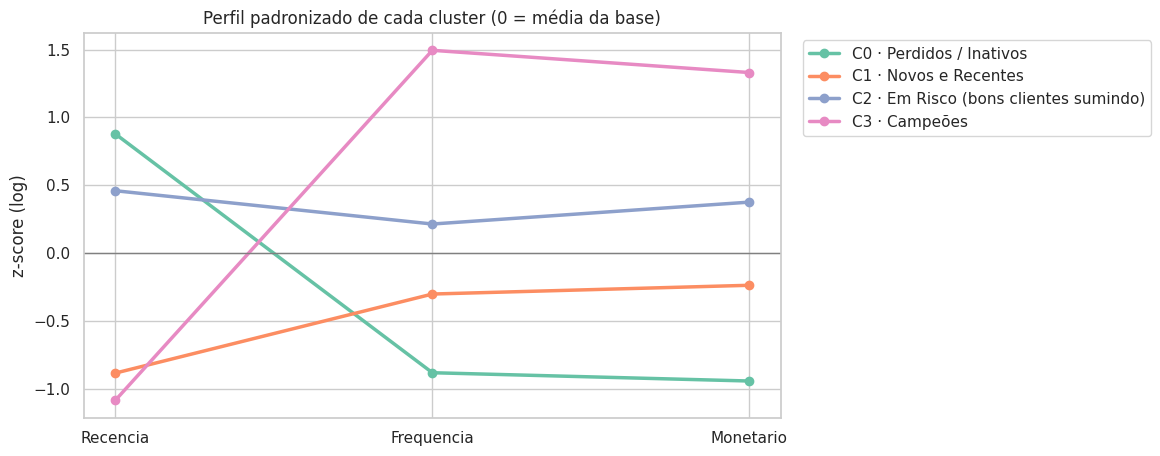

In [27]:
# "Snake plot": média padronizada (z-score do log) de cada variável por cluster
snake = pd.DataFrame(X, columns=RFM).assign(Cluster=clientes["Cluster"].values) \
          .groupby("Cluster").mean()
snake.index = ORDEM_SEG

plt.figure(figsize=(9, 5))
for seg, linha in snake.iterrows():
    plt.plot(RFM, linha.values, marker="o", lw=2.5, label=seg)
plt.axhline(0, c="gray", lw=1)
plt.title("Perfil padronizado de cada cluster (0 = média da base)")
plt.ylabel("z-score (log)"); plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

O *snake plot* resume a "assinatura" de cada grupo em relação à média da base: **Campeões** acima da média em F e M e abaixo em R (bom); **Perdidos** o oposto; **Novos** recentes mas ainda abaixo da média em F e M; **Em Risco** acima da média em F e M, mas com recência alta.

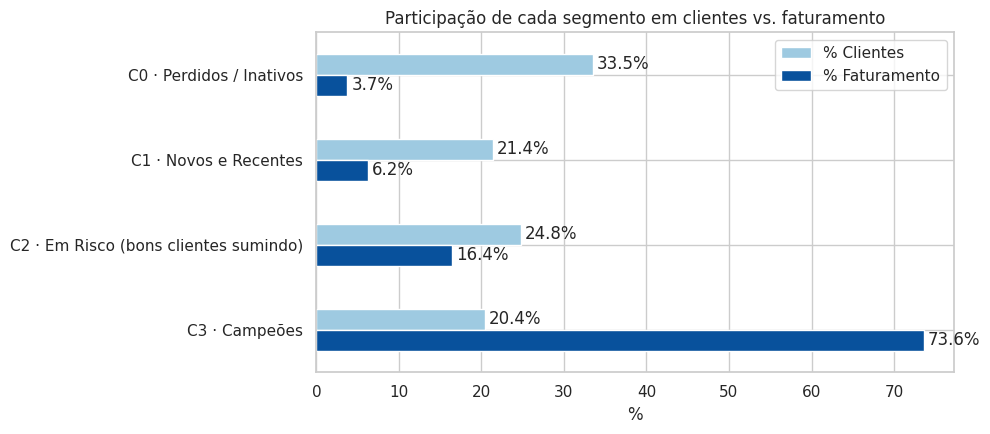

In [28]:
peso = perfil[["% Clientes", "% Faturamento"]].copy()
peso.index = ORDEM_SEG
ax = peso.plot.barh(figsize=(10, 4.5), color=["#9ecae1", "#08519c"])
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.1f%%", padding=3)
ax.set_title("Participação de cada segmento em clientes vs. faturamento")
ax.set_xlabel("%"); ax.invert_yaxis(); plt.tight_layout(); plt.show()

**Concentração de receita (Pareto):** ~20% dos clientes (Campeões) geram ~74% do faturamento, enquanto ~33% (Perdidos) geram menos de 4%.

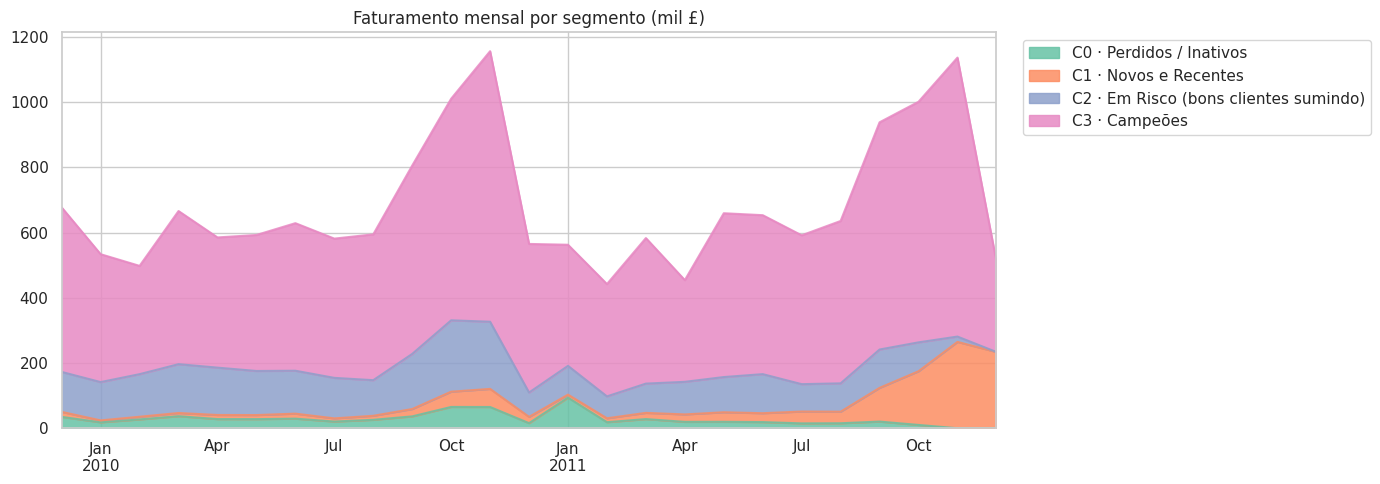

In [29]:
v = vendas.merge(clientes[["Segmento"]], left_on="Customer ID", right_index=True)
v_liq = df.merge(clientes[["Segmento"]], left_on="Customer ID", right_index=True)  # inclui devoluções
mensal_seg = v.pivot_table(index="Mes", columns="Segmento", values="Valor", aggfunc="sum")[ORDEM_SEG]
(mensal_seg / 1e3).plot.area(figsize=(14, 5), alpha=.85)
plt.title("Faturamento mensal por segmento (mil £)"); plt.xlabel("")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left"); plt.tight_layout(); plt.show()

**Dinâmica no tempo:** os Campeões sustentam o faturamento o ano todo. A faixa dos "Em Risco" foi forte em 2010 e encolhe em 2011 — mostra a **receita que a empresa deixou de ter** com esses clientes. Já os "Novos" crescem muito na temporada de Natal de 2011.

Produtos que mais geram receita em cada segmento (útil para campanhas e para o planejamento de estoque/logística):

In [30]:
for seg in ORDEM_SEG:
    top = (v_liq[v_liq["Segmento"] == seg].groupby("Description")["Valor"].sum()
           .sort_values(ascending=False).head(5))
    print(f"\n{seg}")
    for desc, val in top.items():
        print(f"   £{val:>12,.0f}  {desc}")


C0 · Perdidos / Inativos
   £       6,911  WHITE HANGING HEART T-LIGHT HOLDER
   £       5,835  REGENCY CAKESTAND 3 TIER
   £       3,421  ASSORTED COLOUR BIRD ORNAMENT
   £       3,265  PARTY BUNTING
   £       3,040  VINTAGE UNION JACK BUNTING

C1 · Novos e Recentes
   £       9,189  REGENCY CAKESTAND 3 TIER
   £       8,065  WHITE HANGING HEART T-LIGHT HOLDER
   £       7,279  ASSORTED COLOUR BIRD ORNAMENT
   £       7,192  PAPER CHAIN KIT 50'S CHRISTMAS 
   £       5,431  BAKING SET 9 PIECE RETROSPOT 

C2 · Em Risco (bons clientes sumindo)
   £      45,300  WHITE HANGING HEART T-LIGHT HOLDER
   £      39,620  PICNIC BASKET WICKER 60 PIECES
   £      31,837  REGENCY CAKESTAND 3 TIER
   £      19,445  PARTY BUNTING
   £      16,980  ASSORTED COLOUR BIRD ORNAMENT

C3 · Campeões
   £     214,250  REGENCY CAKESTAND 3 TIER
   £     177,441  WHITE HANGING HEART T-LIGHT HOLDER
   £     113,780  JUMBO BAG RED RETROSPOT
   £      95,965  ASSORTED COLOUR BIRD ORNAMENT
   £      75,744  PARTY

Os mesmos "carros-chefe" (suporte de bolo *Regency*, porta-velas *White Hanging Heart*, bandeirolas *Party Bunting*) aparecem em todos os segmentos — são os produtos de **entrada e de recompra**. Garantir disponibilidade em estoque desses itens, principalmente antes de setembro, protege a receita de todos os grupos.

Distribuição dos segmentos dentro de cada mercado (Reino Unido x exterior):

In [31]:
pd.crosstab(clientes["Segmento"], clientes["ReinoUnido"].map({True: "Reino Unido", False: "Exterior"}),
            normalize="columns").reindex(ORDEM_SEG).mul(100).round(1)

ReinoUnido,Exterior,Reino Unido
Segmento,,
C0 · Perdidos / Inativos,27.70,34.00
C1 · Novos e Recentes,22.40,21.30
C2 · Em Risco (bons clientes sumindo),27.70,24.50
C3 · Campeões,22.20,20.20


### Exportação
Salvamos a lista de clientes com seu segmento — é o entregável prático para o CRM/time comercial.

In [32]:
clientes.reset_index()[["Customer ID", "Segmento", "Recencia", "Frequencia", "Monetario",
                        "TicketMedio", "Pais"]] \
        .to_csv("clientes_segmentados.csv", index=False)
print("Arquivo 'clientes_segmentados.csv' gerado — pode ser entregue ao time comercial/CRM.")

Arquivo 'clientes_segmentados.csv' gerado — pode ser entregue ao time comercial/CRM.


## 10. Conclusões e recomendações para o CEO

**Solução:** segmentamos ~5,8 mil clientes pelo comportamento de compra (RFM) com **K-Means (k=4)**, escolhido após comparação com Hierárquico (Ward) e DBSCAN e avaliação por Cotovelo, Silhueta, Davies-Bouldin e Calinski-Harabasz.

**Principais resultados**
- A receita é **muito concentrada**: 1 em cada 5 clientes (Campeões) gera ~3/4 do faturamento.
- Um quarto da carteira (**Em Risco**) já foi relevante e está se afastando — ~16% da receita histórica em jogo.
- Há uma nova safra de clientes (**Novos e Recentes**) chegando na temporada de 2011.
- Um terço dos clientes comprou uma única vez (**Perdidos**).

**Recomendações por segmento**

| Segmento | Objetivo | Ações sugeridas |
|---|---|---|
| **C3 · Campeões** | Reter e proteger | Gerente de conta dedicado; programa de fidelidade/desconto por volume; acesso antecipado à coleção de Natal; prioridade no estoque e na entrega; monitorar qualquer aumento na recência como alerta de churn |
| **C2 · Em Risco** | Reativar | Campanha de "volta" com cupom com prazo; contato ativo do comercial com os de maior valor histórico; pesquisa de motivo de saída (preço? prazo? concorrência?); disparar campanha em **agosto/setembro**, antes da temporada |
| **C1 · Novos e Recentes** | Converter em Campeões | Régua de *onboarding* (2º e 3º pedido com incentivo); recomendação de produtos complementares para aumentar a variedade; frete grátis acima de um valor mínimo |
| **C0 · Perdidos** | Custo baixo de reativação | Apenas campanhas automáticas e baratas (e-mail sazonal); não investir esforço comercial individual; usar o grupo para testar ofertas |

**Logística / estoque**
- Planejar estoque e capacidade de entrega para o pico de **setembro a novembro**;
- Garantir disponibilidade dos produtos carro-chefe, que sustentam todos os segmentos;
- Concentrar a operação em dias úteis, 10h–15h, quando acontecem os pedidos.

**Próximos passos e limitações**
- ~23% das transações não têm cliente identificado: incentivar o cadastro aumentaria a cobertura da análise;
- Rodar a segmentação periodicamente (ex.: todo mês) e acompanhar a migração de clientes entre segmentos;
- Medir o resultado das ações com grupos de controle (teste A/B).